# 04 - Backtest and model choice

Rolling test: for each test month (May, June, July) every part is fitted on the earlier months only.
Training orders must have ended before the test month starts.

**Demand assumption (moderate, k = 3):** share of orders kept = exp(-3 x (our price / price paid - 1)), at most 1.5.
The price paid is Jasper's real price for that order. We also report no, low (k = 1.5) and high (k = 6) sensitivity.

**Choice rule for a feature block:** keep it only if it improves both the pooled prediction error (Poisson
deviance) and the pooled profit under moderate demand, and both in at least 2 of the 3 months.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

In [2]:
from pricing.data import load_orders, load_btc
from pricing.features import market_features
from pricing.pipeline import backtest, Config
from pricing.evaluate import summarize, poisson_deviance, bootstrap_gain, calibration_table, expected_profit
from pricing.rules import K_SCENARIOS
from dataclasses import asdict

train = load_orders("train"); btc = load_btc(); mkt = market_features(btc)
X = pd.read_parquet(OUT / "features_train.parquet").join(pd.read_parquet(OUT / "external_train.parquet"))
status = json.loads((OUT / "external_status.json").read_text())
FOLDS = ["2026-05-01", "2026-06-01", "2026-07-01"]
EVENTS = ("event_in_window", "hours_to_event", "hours_since_event")
FNG = ("fng", "fng_change7")
NEWS = ("news_tone", "news_tone24", "news_volume_ratio")
MARKET = ("dur", "mny_sd", "vol_gap", "rv_trend", "dir_move")
configs = {
    "hybrid_constant": Config(),
    "hybrid_events": Config(risk_features=EVENTS),
    "hybrid_fear_greed": Config(risk_features=FNG),
    "hybrid_events_fear_greed": Config(risk_features=EVENTS + FNG),
    "hybrid_size_capped": Config(risk_features=("size",)),
    "hybrid_market": Config(risk_features=MARKET),
    "hybrid_all_glm": Config(risk_features=MARKET + ("size", "put", "strike_calc", "rebuilt", "weekend") + EVENTS + FNG),
    "hybrid_all_gbm": Config(risk_features=("mny_sd", "vol_gap", "rv_trend", "dir_move") + EVENTS + FNG, risk_kind="gbm"),
    "hybrid_events_const_reference": Config(risk_features=EVENTS, ref_kind="const"),
}
if status.get("news_available"):
    configs["hybrid_news"] = Config(risk_features=NEWS)
    configs["hybrid_events_news"] = Config(risk_features=EVENTS + NEWS)
res = backtest(train, X, btc, mkt, FOLDS, configs)
res.to_parquet(OUT / "backtest_prices.parquet")
print(f"{len(configs)} setups x {len(FOLDS)} months, {res.index.nunique():,} test orders")

9 setups x 3 months, 5,806 test orders


## Results per method

In [3]:
rows = []
ref_run = res[res["config"] == "hybrid_constant"]
bench = {"Jasper real price": lambda g, t: t["paid"].to_numpy(),
         "base price x 1": lambda g, t: g["bench_base_x1"].to_numpy(),
         "base price x best constant": lambda g, t: g["bench_base_x_c"].to_numpy(),
         "own fair value x best constant": lambda g, t: g["bench_fv_x_c"].to_numpy()}
for fold, g in ref_run.groupby("fold"):
    t = train.loc[g.index]
    for name, f in bench.items():
        s = summarize(f(g, t), t); s.update(fold=fold, method=name, kind="benchmark"); rows.append(s)
for (fold, cfg), g in res.groupby(["fold", "config"]):
    t = train.loc[g.index]
    s = summarize(g["premium_per_BTC"].to_numpy(), t)
    s.update(fold=fold, method=cfg, kind="hybrid",
             deviance=poisson_deviance(t["post_payout"], g["expected_payout_per_BTC"], t["qty"]))
    rows.append(s)
r = pd.DataFrame(rows)
r.to_csv(OUT / "backtest_by_fold.csv", index=False)
profit_cols = ["profit_none", "profit_low", "profit_moderate", "profit_high"]
summary = r.groupby(["kind", "method"])[profit_cols + ["deviance"]].sum(min_count=1)
summary = summary.join(r.groupby(["kind", "method"])[["median_price_vs_paid", "share_above_1.5x_paid", "share_below_paid", "loss_ratio_moderate"]].mean())
summary = summary.sort_values("profit_moderate", ascending=False)
summary.to_csv(OUT / "backtest_summary.csv")
summary.round(3)

profit_none  profit_low  profit_moderate  profit_high  deviance  median_price_vs_paid  share_above_1.5x_paid  share_below_paid  loss_ratio_moderate
kind      method                                                                                                                                                                             
benchmark base price x best constant       84,662.444  53,044.223       38,383.057   25,835.572       NaN                 1.295                  0.246             0.250                0.696
hybrid    hybrid_events_const_reference    65,206.002  44,460.644       34,649.202   26,171.167 1,194.730                 1.202                  0.180             0.304                0.746
          hybrid_events                    51,555.978  39,908.842       34,123.541   28,214.282 1,194.730                 1.160                  0.126             0.299                0.768
          hybrid_events_fear_greed         55,217.239  40,536.765       33,812.982   27,541.907 1,204.559                 1.156                  0.134             0.318                0.782
          hybrid_constant                  47,775.381  38,670.624       32,815.326   25,842.108 1,196.513                 1.172                  0.083             0.307                0.777
          hybrid_fear_greed                49,859.342  38,754.526       32,414.819   25,807.148 1,205.509                 1.134                  0.107             0.339                0.800
          hybrid_market                    50,521.234  39,161.347       32,309.704   25,586.452 1,213.626                 1.146                  0.089             0.301                0.798
          hybrid_size_capped               47,194.355  37,657.859       31,488.201   24,182.644 1,198.314                 1.087                  0.061             0.404                0.782
          hybrid_all_gbm                   55,602.844  38,236.190       28,980.694   21,089.462 1,203.149                 1.173                  0.120             0.304                0.788
benchmark own fair value x best constant  106,723.231  45,540.076       25,782.316   12,113.596       NaN                 1.283                  0.314             0.271                0.740
hybrid    hybrid_all_glm                   51,440.138  30,945.758       24,111.009   19,964.567 1,280.265                 1.038                  0.107             0.455                0.850
benchmark Jasper real price                15,195.314  15,195.314       15,195.314   15,195.314       NaN                 1.000                  0.000             0.000                0.906
          base price x 1                  -57,176.443 -81,929.719      -85,659.882  -86,675.112       NaN                 0.697                  0.005             0.957                1.296

In [4]:
r.pivot_table(index="method", columns="fold", values="profit_moderate").round(0).sort_values("2026-07")

fold,2026-05,2026-06,2026-07
method,,,
base price x 1,"-2,382.000","-36,549.000","-46,730.000"
hybrid_all_glm,"2,547.000","21,351.000",213.000
Jasper real price,"4,620.000","6,257.000","4,319.000"
own fair value x best constant,"3,796.000","16,778.000","5,208.000"
hybrid_market,"4,127.000","16,845.000","11,337.000"
hybrid_fear_greed,"4,125.000","15,983.000","12,307.000"
hybrid_all_gbm,"5,112.000","11,322.000","12,547.000"
hybrid_constant,"5,112.000","14,896.000","12,808.000"
hybrid_events_fear_greed,"4,411.000","16,347.000","13,056.000"


## Choice of the feature block

In [5]:
dev = r[r.kind == "hybrid"].pivot(index="method", columns="fold", values="deviance")
prof = r[r.kind == "hybrid"].pivot(index="method", columns="fold", values="profit_moderate")
base_name = "hybrid_constant"
choice = []
for m in dev.index:
    if m == base_name or m.endswith("_const_reference"):   # reference-price variant: decided separately below
        continue
    dev_folds = int((dev.loc[m] < dev.loc[base_name]).sum())
    prof_folds = int((prof.loc[m] > prof.loc[base_name]).sum())
    dev_pool = dev.loc[m].sum() < dev.loc[base_name].sum()
    prof_pool = prof.loc[m].sum() > prof.loc[base_name].sum()
    choice.append({"setup": m, "deviance better (months)": dev_folds, "profit better (months)": prof_folds,
                   "deviance better (pooled)": dev_pool, "profit better (pooled)": prof_pool,
                   "passes": dev_pool and prof_pool and dev_folds >= 2 and prof_folds >= 2,
                   "profit_moderate": prof.loc[m].sum()})
choice = pd.DataFrame(choice).sort_values("profit_moderate", ascending=False)
passing = choice[choice["passes"]]
selected = passing.iloc[0]["setup"] if len(passing) else base_name
choice.to_csv(OUT / "feature_choice.csv", index=False)
print("selected setup:", selected)
choice

selected setup: hybrid_events


,setup,deviance better (months),profit better (months),deviance better (pooled),profit better (pooled),passes,profit_moderate
2,hybrid_events,2,3,True,True,True,"34,123.541"
3,hybrid_events_fear_greed,1,2,False,True,False,"33,812.982"
4,hybrid_fear_greed,1,1,False,False,False,"32,414.819"
5,hybrid_market,0,1,False,False,False,"32,309.704"
6,hybrid_size_capped,2,2,False,False,False,"31,488.201"
0,hybrid_all_gbm,1,0,False,False,False,"28,980.694"
1,hybrid_all_glm,1,1,False,False,False,"24,111.009"


## Reference price: model or one constant markup?

Rule (fixed before the test): keep the reference-price **model** (planned design) unless one constant markup gives more
profit under **all three** demand levels (low, moderate, high). The demand rule of Jasper Vault is unknown, so a choice
must not depend on one assumed level.

In [6]:
pair = summary.reset_index().set_index("method").loc[["hybrid_events", "hybrid_events_const_reference"],
                                                     ["profit_low", "profit_moderate", "profit_high", "share_above_1.5x_paid"]]
const_better_all = bool((pair.loc["hybrid_events_const_reference", ["profit_low", "profit_moderate", "profit_high"]]
                         > pair.loc["hybrid_events", ["profit_low", "profit_moderate", "profit_high"]]).all())
ref_kind = "const" if const_better_all else "model"
print("reference price:", ref_kind)
pair.round(3)

reference price: model


,profit_low,profit_moderate,profit_high,share_above_1.5x_paid
method,,,,
hybrid_events,"39,908.842","34,123.541","28,214.282",0.126
hybrid_events_const_reference,"44,460.644","34,649.202","26,171.167",0.180


In [7]:
final_cfg = configs[selected]
if ref_kind == "const" and selected == "hybrid_events":
    selected, final_cfg = "hybrid_events_const_reference", configs["hybrid_events_const_reference"]
cfg = asdict(final_cfg)
(OUT / "selected_config.json").write_text(json.dumps({"name": selected, "config": cfg}, indent=1))
print("final setup:", selected)
cfg

final setup: hybrid_events


{'k': 3.0,
 'cap_lo': 0.85,
 'cap_hi': 1.6,
 'risk_features': ('event_in_window', 'hours_to_event', 'hours_since_event'),
 'risk_kind': 'glm',
 'risk_alpha': 0.1,
 'size_cap': (0.8, 1.5),
 'ref_kind': 'model'}

## Gain against Jasper's real price, with a 90% confidence interval (whole days resampled)

In [8]:
days = train.loc[ref_run.index, "created"].dt.date.to_numpy()
t_all = train.loc[ref_run.index]
jasper = expected_profit(t_all["paid"], t_all["paid"], t_all["post_payout"], t_all["qty"], 3.0)
ci = []
candidates = {"selected: " + selected: res[res.config == selected].loc[ref_run.index, "premium_per_BTC"],
              "hybrid_constant": ref_run["premium_per_BTC"],
              "base price x best constant": ref_run["bench_base_x_c"]}
for name, P in candidates.items():
    for scen, k in K_SCENARIOS.items():
        new = expected_profit(P, t_all["paid"], t_all["post_payout"], t_all["qty"], k)
        ref = expected_profit(t_all["paid"], t_all["paid"], t_all["post_payout"], t_all["qty"], k)
        gain, lo, hi, p = bootstrap_gain(new, ref, days)
        ci.append({"method": name, "demand": scen, "gain": gain, "ci_low": lo, "ci_high": hi, "P(gain > 0)": p})
ci = pd.DataFrame(ci)
ci.to_csv(OUT / "bootstrap_gain.csv", index=False)
ci.round(2)

,method,demand,gain,ci_low,ci_high,P(gain > 0)
0,selected: hybrid_events,none,"36,360.660","26,835.070","46,277.500",1.000
1,selected: hybrid_events,low,"24,713.530","15,507.980","35,288.520",1.000
2,selected: hybrid_events,moderate,"18,928.230","6,481.930","33,832.050",1.000
3,selected: hybrid_events,high,"13,018.970","-3,917.620","33,250.070",0.880
4,hybrid_constant,none,"32,580.070","24,169.640","41,046.410",1.000
5,hybrid_constant,low,"23,475.310","15,209.480","32,896.440",1.000
6,hybrid_constant,moderate,"17,620.010","5,895.180","30,998.100",1.000
7,hybrid_constant,high,"10,646.790","-5,581.840","29,641.510",0.850
8,base price x best constant,none,"69,467.130","58,002.410","81,663.510",1.000
9,base price x best constant,low,"37,848.910","24,712.240","52,923.660",1.000


## Segments: selected setup against Jasper's real price (moderate demand, May-July)

In [9]:
sel = res[res.config == selected]
t = train.loc[sel.index].copy()
t["ours"] = expected_profit(sel["premium_per_BTC"], t["paid"], t["post_payout"], t["qty"], 3.0)
t["jasper"] = expected_profit(t["paid"], t["paid"], t["post_payout"], t["qty"], 3.0)
t["price_ratio"] = sel["premium_per_BTC"] / t["paid"]
t["size_group"] = pd.qcut(t["qty"], 5, labels=["smallest 20%", "2", "3", "4", "largest 20%"])
t["type"] = np.where(t["is_put"], "Put", "Call")
t["duration"] = (t["duration_s"] / 3600).map(lambda h: f"{h:g} h")
seg = []
for col in ["duration", "type", "size_group"]:
    g = t.groupby(col, observed=True).agg(orders=("qty", "size"), jasper_profit=("jasper", "sum"),
                                          our_profit=("ours", "sum"), median_price_ratio=("price_ratio", "median"))
    g.insert(0, "segment", col); seg.append(g.reset_index().rename(columns={col: "group"}))
seg = pd.concat(seg)
seg.to_csv(OUT / "segments.csv", index=False)
seg.round(2)

,group,segment,orders,jasper_profit,our_profit,median_price_ratio
0,0.5 h,duration,2116,"16,175.740","12,970.720",0.910
1,1 h,duration,531,"1,394.630","4,432.140",1.080
2,12 h,duration,46,50.830,57.120,1.120
3,2 h,duration,1021,"5,943.380","9,047.270",1.170
4,24 h,duration,117,845.390,734.640,1.130
5,4 h,duration,1096,"-9,185.870",642.330,1.210
6,8 h,duration,879,-28.800,"6,239.320",1.220
0,Call,type,3169,"20,036.390","28,977.250",1.100
1,Put,type,2637,"-4,841.070","5,146.290",1.120
0,smallest 20%,size_group,1162,228.210,182.980,1.050


In [10]:
calib = calibration_table(sel["expected_payout_per_BTC"], t["post_payout"], t["qty"], bins=5)
calib.to_csv(OUT / "calibration.csv")
calib.round(2)

,orders,predicted_usd,real_usd,real/predicted
bin,,,,
0,"1,162.000","8,412.260","9,945.380",1.180
1,"1,161.000","31,487.860","30,775.310",0.980
2,"1,161.000","48,588.530","63,399.080",1.300
3,"1,161.000","56,551.230","59,449.080",1.050
4,"1,161.000","55,120.360","56,042.130",1.020


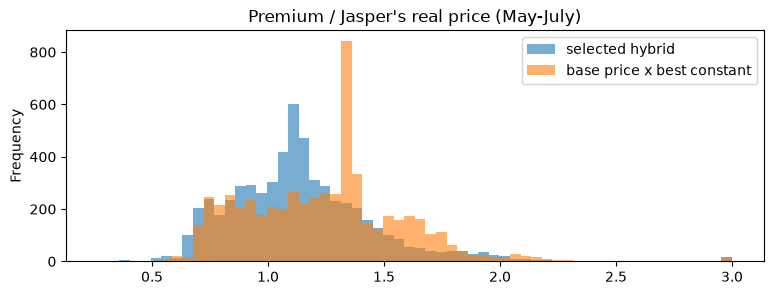

In [11]:
pr = pd.DataFrame({"selected hybrid": sel["premium_per_BTC"] / t["paid"],
                   "base price x best constant": ref_run["bench_base_x_c"] / t["paid"]})
pr.to_parquet(OUT / "price_ratios.parquet")
pr.clip(0, 3).plot.hist(bins=60, alpha=0.6, figsize=(9, 3), title="Premium / Jasper's real price (May-July)"); plt.show()